In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()

100%|██████████| 9.91M/9.91M [00:00<00:00, 57.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.75MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.6MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [6]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 1.550
Epoch 2/15, Loss: 1.547
Epoch 3/15, Loss: 1.545
Epoch 4/15, Loss: 1.542
Epoch 5/15, Loss: 1.540
Epoch 6/15, Loss: 1.538
Epoch 7/15, Loss: 1.536
Epoch 8/15, Loss: 1.535
Epoch 9/15, Loss: 1.533
Epoch 10/15, Loss: 1.532
Epoch 11/15, Loss: 1.530
Epoch 12/15, Loss: 1.529
Epoch 13/15, Loss: 1.527
Epoch 14/15, Loss: 1.526
Epoch 15/15, Loss: 1.525
Accuracy on images: 94.28


In [4]:
pip install bound-propagation

Note: you may need to restart the kernel to use updated packages.


In [11]:
from bound_propagation import BoundModelFactory, HyperRectangle

model.eval()

eye = torch.eye(10, device=device)

W = torch.stack([
    eye[y] - eye[j]
    for y in range(10)
    for j in range(10)
])

diff_layer = nn.Linear(10, 100, bias=False).to(device)

with torch.no_grad():
    diff_layer.weight.copy_(W)

net = BoundModelFactory().build(nn.Sequential(
    model[1].fc,
    nn.ReLU(),
    model[1].fc2,
    diff_layer
))

accs = []

with torch.no_grad():
    for epsilon in np.arange(1, 11) / 100:
        verified = 0
        total = 0

        for x, y in test_loader:
            x = x.to(device).view(x.size(0), -1)
            y = y.to(device)

            lower = (x - epsilon).clamp(0, 1)
            upper = (x + epsilon).clamp(0, 1)

            lower = (lower - 0.1307) / 0.3081
            upper = (upper - 0.1307) / 0.3081

            input_bounds = HyperRectangle(lower, upper)
            ibp_bounds = net.ibp(input_bounds)

            margin_lower = ibp_bounds.lower.reshape(-1, 10, 10)
            margin_lower = margin_lower[torch.arange(y.size(0), device=device), y]

            verified += (margin_lower >= 0).all(dim=1).sum().item()
            total += y.size(0)

        accuracy = 100 * verified / total
        accs.append(accuracy)

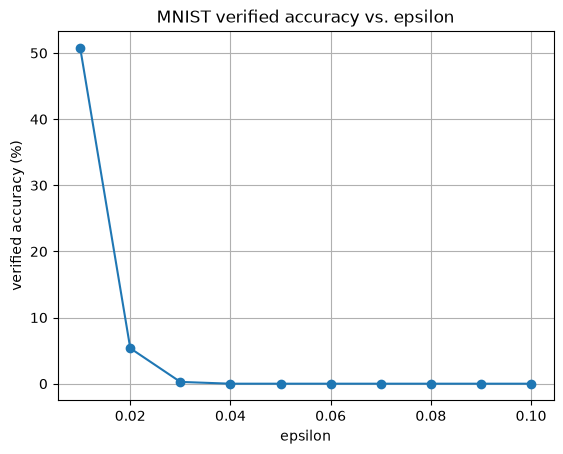

In [12]:
epsilons = np.arange(0.01, 0.101, 0.01)

plt.plot(epsilons, accs, marker='o')
plt.xlabel("epsilon")
plt.ylabel("verified accuracy (%)")
plt.title("MNIST verified accuracy vs. epsilon")
plt.grid(True)
plt.show()